# Module 2 - Self-attention mathematics

This notebook is the recommended `notebooks/02_attention_math.ipynb` from the PRD's repository layout. It runs the real `src.attention.self_attention` module on the configured 15-base sequence and displays the actual Q/K/V shapes and attention matrix.

In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from src import config
from src.attention import self_attention as sa

sequence = config.PIPELINE_DEFAULT_SEQUENCE
print('sequence:', sequence)
print('length:', len(sequence))
print('seed:', config.ATTENTION_SEED)

sequence: ACGUACGUACGGCUA
length: 15
seed: 2024


In [2]:
result = sa.run_self_attention(sequence=sequence)
print('input_mode:', result.input_mode)
print('Q shape:', tuple(result.q.shape))
print('K shape:', tuple(result.k.shape))
print('V shape:', tuple(result.v.shape))
print('attention shape:', tuple(result.weights.shape))
print('scaling factor: sqrt(d_k) =', np.sqrt(result.d_k))
print('max row-sum error:', float(np.abs(result.row_sums() - 1.0).max()))

input_mode: nucleotide
Q shape: (15, 8)
K shape: (15, 8)
V shape: (15, 8)
attention shape: (15, 15)
scaling factor: sqrt(d_k) = 2.8284271247461903
max row-sum error: 1.1920928955078125e-07


Top pairs (from_index, to_index, weight):
   1 ->  0  0.079073
   1 -> 14  0.079073
   1 ->  8  0.079073
   1 ->  4  0.079073
   5 ->  8  0.079073


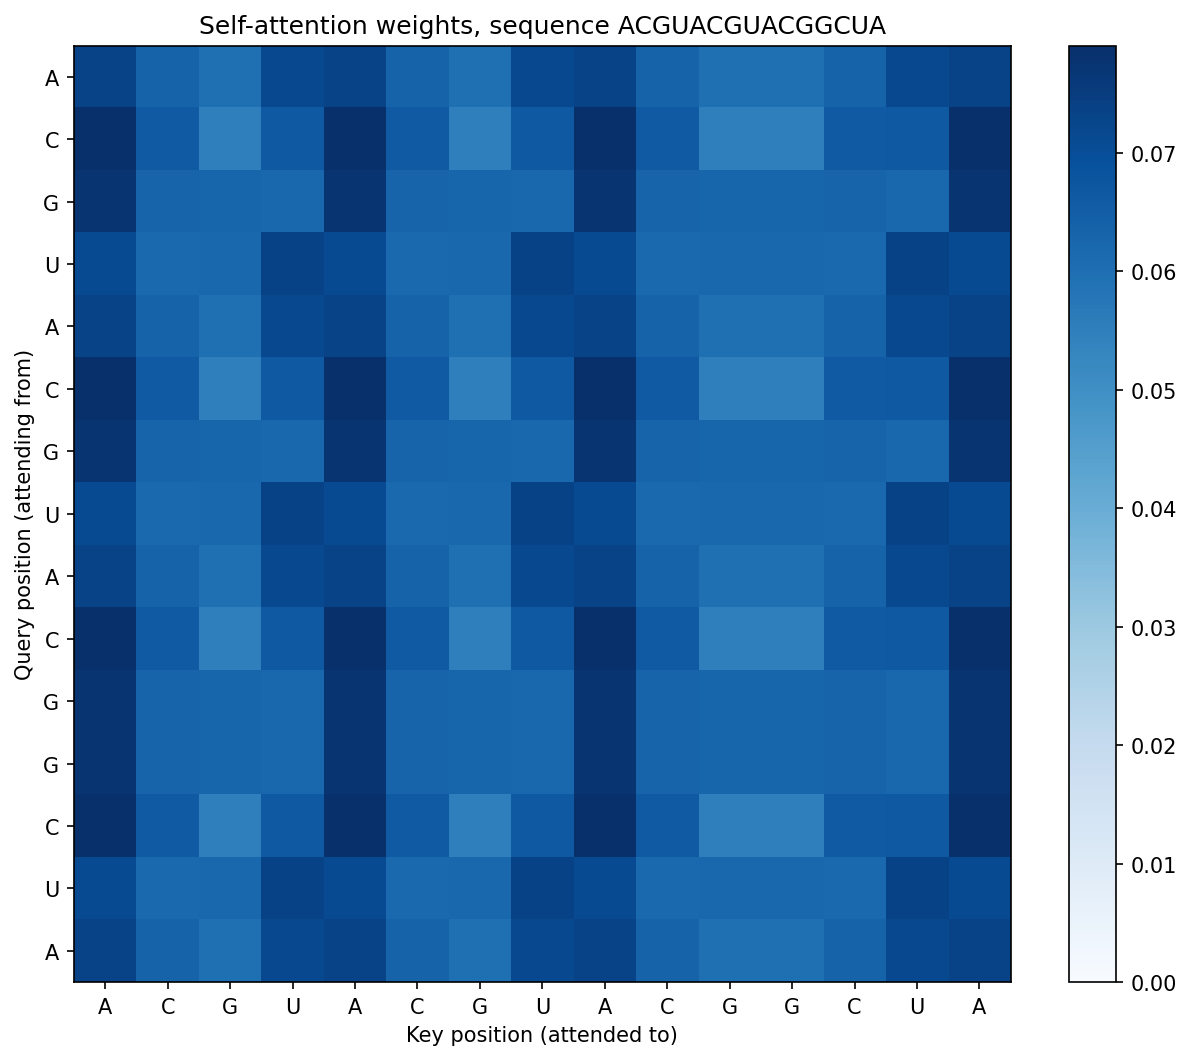

In [3]:
weights = result.weight_matrix()
fig, ax = plt.subplots(figsize=(8.5, 7.2))
image = ax.imshow(weights, cmap='Blues', vmin=0, vmax=weights.max())
ax.set_xticks(range(result.seq_len), labels=result.sequence)
ax.set_yticks(range(result.seq_len), labels=result.sequence)
ax.set_xlabel('Key position (attended to)')
ax.set_ylabel('Query position (attending from)')
ax.set_title(f'Self-attention weights, sequence {sequence}')
fig.colorbar(image, ax=ax, fraction=0.046)
fig.tight_layout()
print('Top pairs (from_index, to_index, weight):')
for i, j, weight in result.top_pairs(5):
    print(f'  {i:2d} -> {j:2d}  {weight:.6f}')

## What the heatmap shows

Each row is a query position and each column is a key position. The module projects the embedded sequence into three matrices: Q = XWq, K = XWk and V = XWv. It scores every query against every key with `(Q K^T) / sqrt(d_k)`, applies a row-wise softmax, and multiplies the resulting weights by V. The heatmap is that weight matrix: a darker cell means the query at that row places more of its attention budget on that key. Every row sums to 1 within 1.19e-07, so the display is a set of probability distributions rather than arbitrary scores.

The projections here are randomly initialised and have not been trained, so the near-uniform pattern is an arithmetic fact, not a biological claim. The notebook demonstrates the mechanics the PRD asks for; it does not assert that any base pair is functionally important.